## What is Machine Learning?

* It is a branch of AI
* Uses data and algorithms to replicate how people learn
* Can use to make classifications and predictions

There are a few general categories of machine learning:
* Supervised – uses [labeled](https://www.datacamp.com/blog/what-is-labeled-data) data sets
    * Classification
    * Regression
* Unsupervised – does not use labeled data sets
    * Clustering
* Reinforcement learning

![Supervised Learning](https://abeyon.com/wp-content/uploads/2018/11/0-1.png)
![Unsupervised Learning](https://abeyon.com/wp-content/uploads/2018/11/0-2.png)

Also see: [https://www.geeksforgeeks.org/types-of-machine-learning/](https://www.geeksforgeeks.org/types-of-machine-learning/)

### Classification
* Uses algorithm to assign data into specific categories
* Examples include support vector machines, decision trees, and random forest

![Decision Tree Example](https://www.ibm.com/content/dam/connectedassets-adobe-cms/worldwide-content/cdp/cf/ul/g/ce/ed/ICLH_Diagram_Batch_03_24A-AI-ML-DecisionTree.png)

### Regression
* Goal is to understand relationship between dependent and independent variable
* Examples include linear regression and logistic regression
    * Consider: y = mx + b
    * y is the dependent variable (what we try to predict)
    * x is the independent variable
    * b is the y intercept
    * m is the slope
    

![Linear Regression Example](https://spss-tutorials.com/img/simple-linear-regression-intercept-in-scatterplot.png)

### Clustering
* Algorithm that assigns similar data into groups
* Popular algorithms include KNN and K-means

![Clustering Example](https://media.geeksforgeeks.org/wp-content/uploads/20250904105944868523/Clustering.webp)

Regression, Classification, or Clustering?
1. Determining if a picture is of a dog or a cat
2. Determining if a patient is at high risk of cancer or not
3. Predict the price of home
4. Determine similar types of customers
5. Determining facial expressions (e.g. happy, mad, ...)
6. Determine the type of a review (e.g. good, bad, ...)
7. Predicting sales value of a product
8. Detecting fraudulent behavior

## Linear Regression Example

We'll bring in the Prestige data set. It lists occupational data and prestige scores."Prestige scores are based on a consensus perceived worthiness and range from 0- 100, with 0 being the lowest and 100 being the highest." See [https://r-packages.io/datasets/Prestige](https://r-packages.io/datasets/Prestige) to learn more about the dataset.

**Note: This is a very quick and dirty example. There is much more that needs to be done to build a correct model.**

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [7]:
# load iris dataset
df = pd.read_csv("prestige.csv")

In [9]:
df

,job,education,income,women,census,type,prestige
0,gov.administrators,13.11,12351,11.16,1113,prof,68.8
1,general.managers,12.26,25879,4.02,1130,prof,69.1
2,accountants,12.77,9271,15.70,1171,prof,63.4
3,purchasing.officers,11.42,8865,9.11,1175,prof,56.8
4,chemists,14.62,8403,11.68,2111,prof,73.5
...,...,...,...,...,...,...,...
97,bus.drivers,7.58,5562,9.47,9171,bc,35.9
98,taxi.drivers,7.93,4224,3.59,9173,bc,25.1
99,longshoremen,8.37,4753,0.00,9313,bc,26.1
100,typesetters,10.00,6462,13.58,9511,bc,42.2


In [11]:
df.describe()

,education,income,women,census,prestige
count,102.000000,102.000000,102.000000,102.000000,102.000000
mean,10.738039,6797.901961,28.979020,5401.774510,46.833333
std,2.728444,4245.922227,31.724931,2644.993215,17.204486
min,6.380000,611.000000,0.000000,1113.000000,14.800000
25%,8.445000,4106.000000,3.592500,3120.500000,35.225000
50%,10.540000,5930.500000,13.600000,5135.000000,43.600000
75%,12.647500,8187.250000,52.202500,8312.500000,59.275000
max,15.970000,25879.000000,97.510000,9517.000000,87.200000


In [ ]:
df.info()

In [13]:
df['type'].value_counts()

type
bc      44
prof    31
wc      23
Name: count, dtype: int64

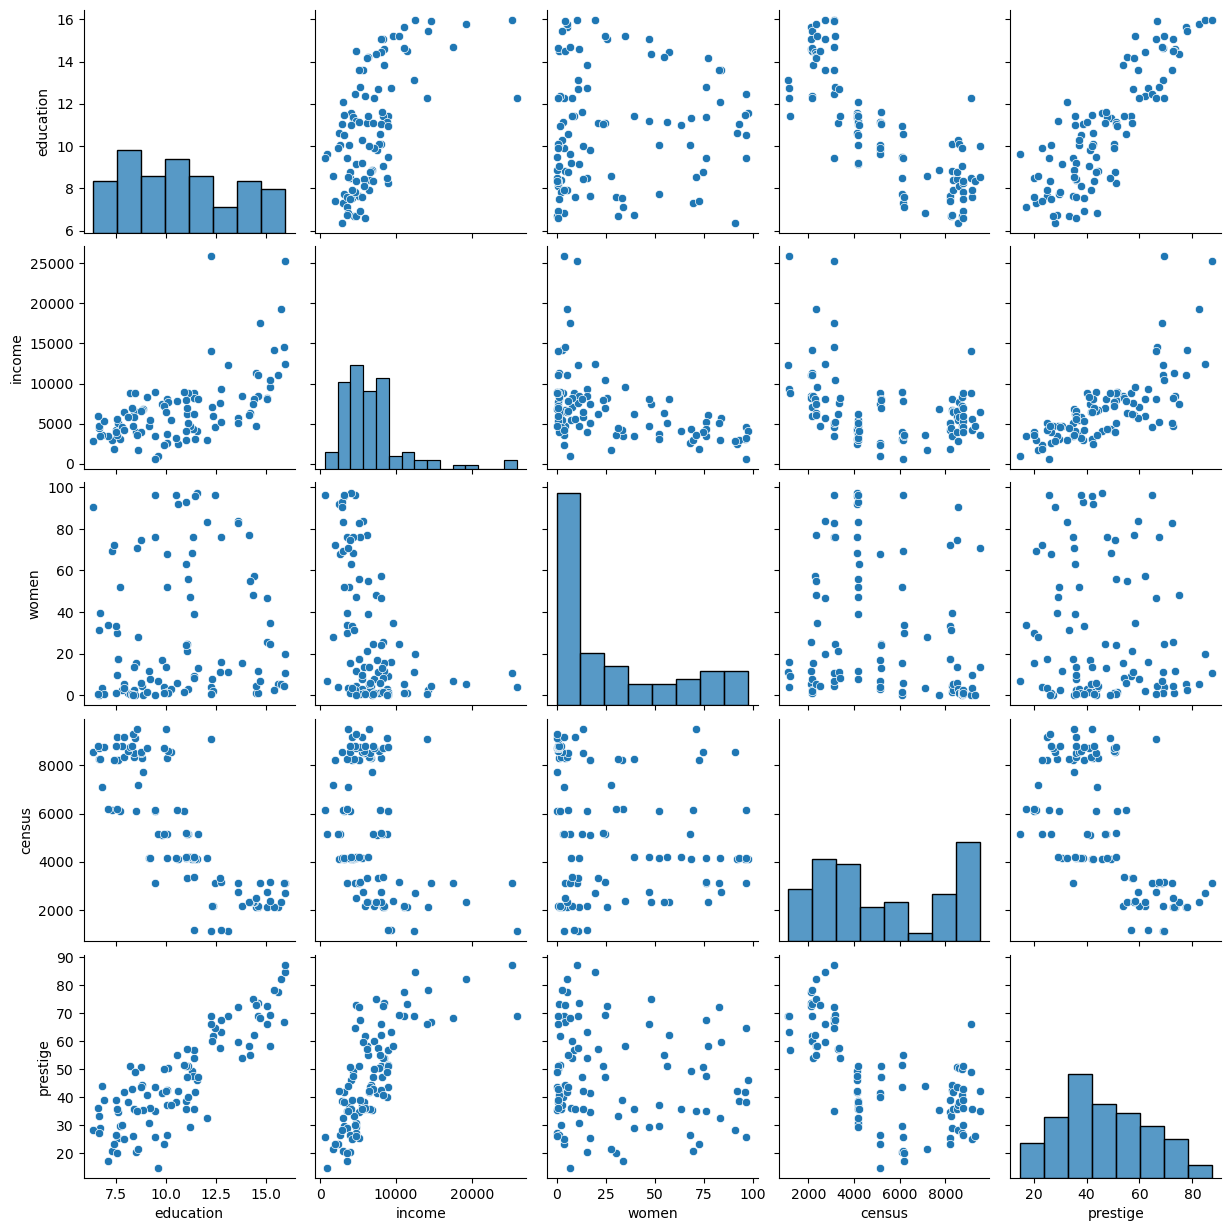

In [15]:
sns.pairplot(data=df)

<Axes: >

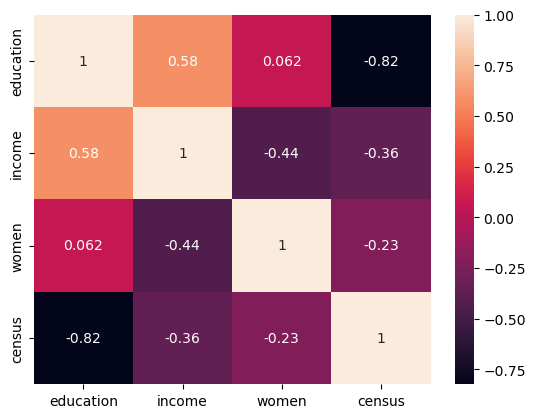

In [17]:
x = df[['education', 'income', 'women', 'census']]
sns.heatmap(x.corr(), annot=True)

In [21]:
x = df[['education', 'income', 'women', 'census']] # independent variables
y = df[['prestige']] # dependent variable

Let's now train the model based on our data.

In [24]:
reg = LinearRegression()
reg.fit(x,y)
print(reg.intercept_)
print(reg.coef_)

[-14.94944031]
[[ 4.65715805e+00  1.28922425e-03 -2.08682032e-03  5.68420955e-04]]


In [27]:
# normally we'd have data to test against that is not the data that we used to train
# this will allow us to evaluation our model better
# for now, let's just try an observation from above and see what this gives us
prediction = reg.predict(np.array([[13.11,12351,11.16,1113]]))
prediction # predicted prestige

C:\Users\alm36\AppData\Local\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([[62.63847405]])

So how good is this model? We'll use the coefficient of determination (R<sup>2</sup>). 

In [29]:
reg.score(x, y)

0.8003869997279731

The above tells use how well the independent variables explain the variation in the dependent variable. So 80% of the variation can be explained by the inputs (independent variables).

See [https://www.interactive-ml.com/linear-regression.html](https://www.interactive-ml.com/linear-regression.html) for another example that helps you understand how to evaluate the model.

### We'll consider next time:

Assumptions of Linear Regression:
* Observations are independent
* There is a linear relationship between independent and dependent variables
* There is not a strong correlation between independent variables
* Normal distribution: errors between observed and predicted values (i.e., the residuals of the regression) should be normally distributed
* Homoskedasticity: residuals have a constant variance (will have the same skatter from regression line) 

Also, don't forget to remove outliers if applicable; these will severely impact results. Note: linear regression does require scaling of features.